![PIC UPV PERTE Chip Chair Logo](https://www.pic-chair.upv.es/wp-content/uploads/2024/05/logo-upv-horizontal.png)
![PIC UPV PERTE Chip Chair Logo](https://www.pic-chair.upv.es/wp-content/uploads/2024/06/logos-perte-chip-1024x119.png)


# Laboratory 1. Waveguides

Welcome to our Photonic Integrated Circuits Laboratory! Throughout the course, we will be using a Python package called [GDSFactory](https://gdsfactory.github.io/gdsfactory/index.html). This is an open-source tool, and is a great alternative to other commercial software like Synopsys Optodesigner, Luceda Photonics, or Lumerical/Interconnect. Since it runs on Python, you have two options for executing your laboratory tasks:

1. **Local installation on your own PC** (Recommended): Please note that we will not spend class time on installing the software. However, feel free to reach out if you need help with the installation.

2. **Cloud Workspace**: Alternatively, you can use a cloud-based solution if the Local installation does not work.

## 0. Imports

For this laboratory you will need the following libraries:

In [101]:
import matplotlib.pyplot as plt
import numpy as np

import tidy3d as td

import gplugins as gp
import gplugins.tidy3d as gt
from gplugins import plot
from gplugins.common.config import PATH

nm = 1e-3
wavelength = np.linspace(1500, 1600,11) * nm
f = td.C_0 / wavelength


## LO.1. Effective index of a waveguide

### 1.1. Materials

We need the refractive index of each material in the cross-section. There are different options to get this information, such as [RefractiveIndex.info](https://refractiveindex.info/) and the [Material Library from Tidy3D](https://docs.flexcompute.com/projects/tidy3d/en/v2.6.0/api/material_library.html#). Here we will load and check the characteristics from the most common materials used in fabrication of photonic circuits: **silicon (Si), silicon nitride (SiNx) and silicon dioxide (SiO2)**.

#### 1.1.1. Crystalline Silicon 

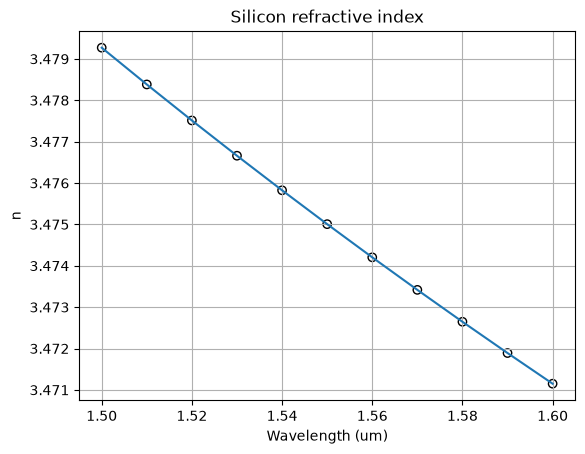

In [102]:
## Material model loaded
si_complex = td.material_library["cSi"]["Li1993_293K"].eps_model(f)
## Check the Tidy3D Docs for more information on the "Variant"

## Index at a particular wavelength
si_index , si_k = td.Medium.eps_complex_to_nk(si_complex)
plt.scatter(wavelength, si_index,edgecolors='k',facecolors='none')
plt.plot(wavelength,si_index)
plt.title("Silicon refractive index")
plt.xlabel("Wavelength (um)")
plt.ylabel("n")
plt.grid()

#### 1.1.2. Silicon Nitride

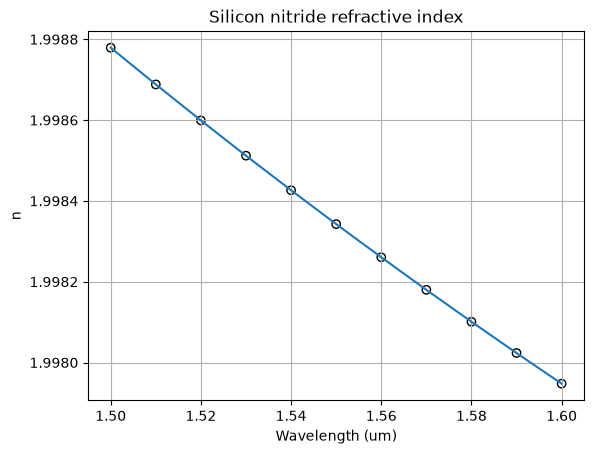

In [103]:
nitride_complex = td.material_library["Si3N4"]["Luke2015PMLStable"].eps_model(f)
nitride_index, nitride_k = td.Medium.eps_complex_to_nk(nitride_complex)
plt.scatter(wavelength,nitride_index,edgecolors='k',facecolors='none')
plt.plot(wavelength, nitride_index)
plt.title("Silicon nitride refractive index")
plt.xlabel("Wavelength (um)")
plt.ylabel("n")
plt.grid()


#### 1.1.3. Silicon Dioxide

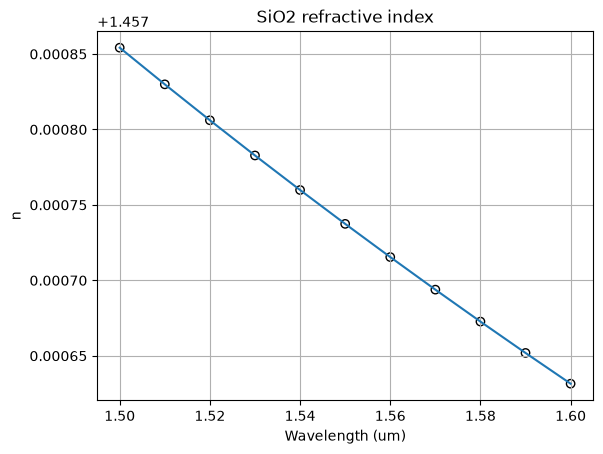

In [104]:
box_complex = td.material_library["SiO2"]["Horiba"].eps_model(f)
box_index, box_k = td.Medium.eps_complex_to_nk(box_complex)
plt.scatter(wavelength,box_index,edgecolors='k',facecolors='None')
plt.plot(wavelength, box_index)
plt.title("SiO2 refractive index")
plt.xlabel("Wavelength (um)")
plt.ylabel("n")
plt.grid()

### 1.2. Cross - Section Definition

In GDSFactory - Tidy3d modesolver we just have to use the [gt.modes.Waveguide()](https://gdsfactory.github.io/gplugins/_autosummary/gplugins.tidy3d.modes.Waveguide.html) function. 
It implements the **deep (rib)** and **shallow (ridge)** waveguide variants. The following example corresponds to a **deep** waveguide for the **silicon nitride** fabrication proccess, this means that the **cladding** material is silicon dioxide and the **core** material is silicon nitride. The waveguide dimensions are 300 nm (height) and 1.2 um (width). We will check it's behavior at 1.55 um. 

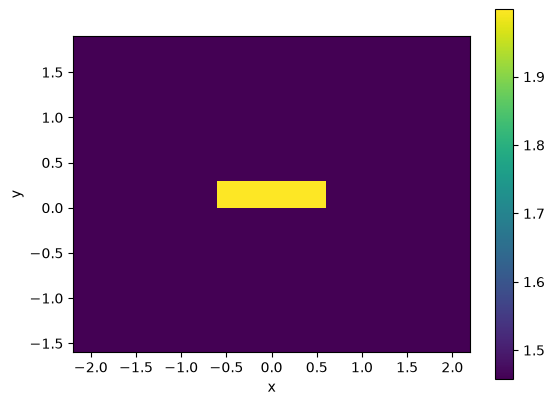

In [105]:
deep_waveguide = gt.modes.Waveguide(
    # Geometrical Parameters
    core_width=1.2, # Waveguide width
    core_thickness=300 * nm, # Waveguide height
    slab_thickness=000 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguide.
    # Materials
    core_material='sin', #  Material of the waveguide
    clad_material='sio2', # Surrounding material
    # Modesolver Parameters
    wavelength=1550 * nm, # Wavelength to simulate
    num_modes=4, # Targeted number of modes to find
    max_grid_scaling=1.5, # Parameters of the grid
    grid_resolution=20, # Parameters of the grid
    cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
    precision='double',
)

deep_waveguide.plot_index()

### 1.3. Simulations

#### 1.3.1. Numerical results

We can find the effective index (n_eff), TE and TM fraction for each particular cross-section.

In [106]:
deep_waveguide.n_eff

2026-10-09 16:50:39.815 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_cf92515ae4232c65.npz.


array([1.60524792+0.00010066j, 1.52829803+0.00017753j,
       1.45072999+0.00019228j, 1.43325817+0.00021838j])

Son modos guiados los que su neff es mayor que el neff del clading material

In [107]:
deep_waveguide.fraction_te

array([0.99505426, 0.01004259, 0.96264794, 0.047651  ])

Estos numeros llamados fracion de te o tm indican que tipo de modo tenemos. Cuando se acercan a 1 en un tipo, pertenecen a ese tipo. En este caso el modo 0 es tipo te y el modo 1 es tipo tm.

Solo tenemos en cuenta los que pertenecen a modos guiados. El resto no son significantes.

In [108]:
deep_waveguide.fraction_tm

array([0.00494574, 0.98995741, 0.03735206, 0.952349  ])

#### 1.3.4. Plots

Cuando buscamos modos TE ploteamos el field Ex, para TM el field Ey.

Text(0.5, 1.0, 'Titulo')

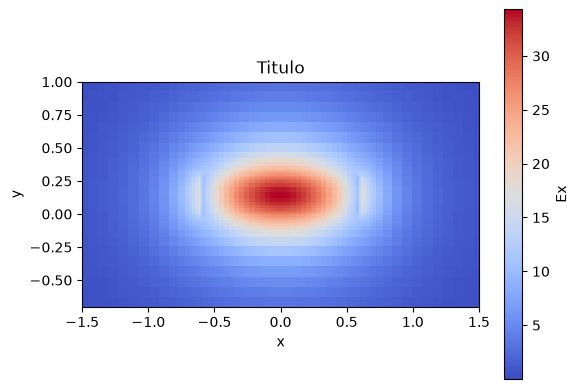

In [109]:
deep_waveguide.plot_field(mode_index=0 , # Mode to be plotted
                          field_name='Ex', # Field to be plotted
                          value='real', # Real - abs - imag
                            cmap='coolwarm', # Suggestions: Change the plot color
                          xlim=(-1.5, 1.5), # Set the x and y limits
                          ylim=(-0.7, 1)
) #
plt.title('Titulo') # You might need this later :)

El modo 1 TE esta muy confinado.

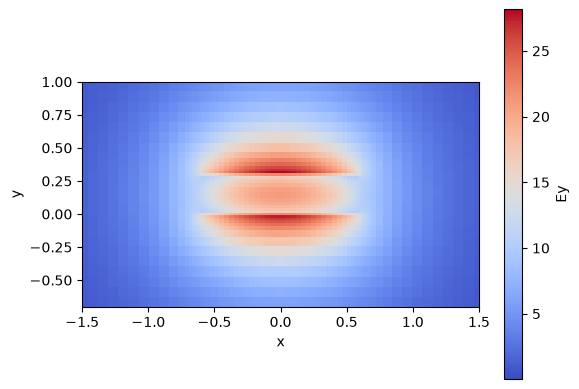

In [110]:
deep_waveguide.plot_field(mode_index=1 , # Mode to be plotted
                          field_name='Ey', # Field to be plotted
                          value='real', # Real - abs - imag
                          cmap='coolwarm', # Suggestions: Change the plot color
                          xlim=(-1.5, 1.5), # Set the x and y limits
                          ylim=(-0.7, 1)) #

Mientrasd que el modo 2 TM no esta tan confinado. Vemos como en las parede superiores e inferiores hay perdidas.

Generalmente el tipo TM sufre mas en las paredes superiores e inferiores, mientras que en el modo TE las laterales. Depende mucho del tipo de frabricacion, pues dependiendo de este la roughness de las paredes cambia.

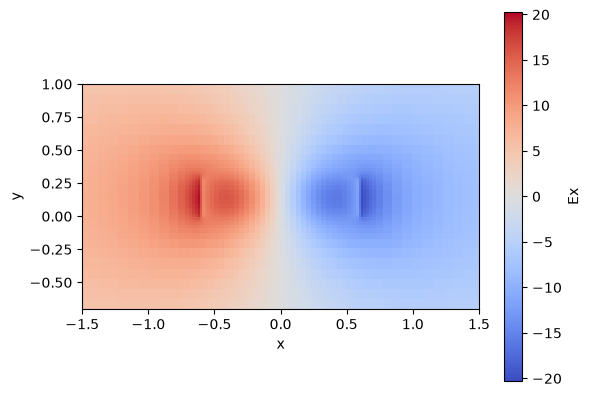

In [111]:
deep_waveguide.plot_field(mode_index=2 , # Mode to be plotted
                          field_name='Ex', # Field to be plotted
                          value='real', # Real - abs - imag
                          cmap='coolwarm', # Suggestions: Change the plot color
                          xlim=(-1.5, 1.5), # Set the x and y limits
                          ylim=(-0.7, 1)) #

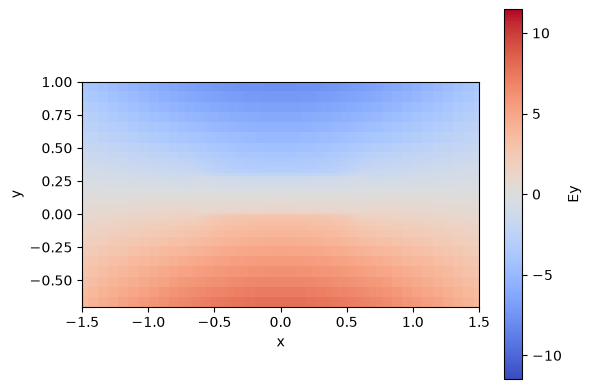

In [112]:
deep_waveguide.plot_field(mode_index=3, # Mode to be plotted
                          field_name='Ey', # Field to be plotted
                          value='real', # Real - abs - imag
                          cmap='coolwarm', # Suggestions: Change the plot color
                          xlim=(-1.5, 1.5), # Set the x and y limits
                          ylim=(-0.7, 1)) #

**Important** 
These results are derived from a numerical method used to solve the EM problem, so they must always be interpreted carefully to assess their accuracy. You must check, for instance, if the value of each index neff is higher than the refractive index of the cladding. 

## LO.2. Width dependence

- Perform a sweep of the **deep** waveguide width. Use the code provided in the following cell or program your own sweep. 

  0%|          | 0/11 [00:00<?, ?it/s]

2026-10-09 16:50:40.865 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_e0f2a62752cad497.npz.
2026-10-09 16:50:40.869 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_cad20f99025f789a.npz.
2026-10-09 16:50:40.871 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_575965d134f345c4.npz.
2026-10-09 16:50:40.875 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_3ca61e62fe85ccf2.npz.
2026-10-09 16:50:40.878 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_8b617c8aef408673.npz.
2026-10-09 16:50:40.880 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_cd84020834745298.npz.
2026-10-09 16:50:40.882 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_df7667b1ace5cc7e.npz.
2026-10-09 16:50:40.884 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_a4e198a34f8f1987.npz.


  0%|          | 0/11 [00:00<?, ?it/s]

2026-10-09 16:50:40.902 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_e0f2a62752cad497.npz.
2026-10-09 16:50:40.905 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_cad20f99025f789a.npz.
2026-10-09 16:50:40.909 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_575965d134f345c4.npz.
2026-10-09 16:50:40.913 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_3ca61e62fe85ccf2.npz.
2026-10-09 16:50:40.917 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_8b617c8aef408673.npz.
2026-10-09 16:50:40.920 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_cd84020834745298.npz.
2026-10-09 16:50:40.923 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_df7667b1ace5cc7e.npz.
2026-10-09 16:50:40.927 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_a4e198a34f8f1987.npz.


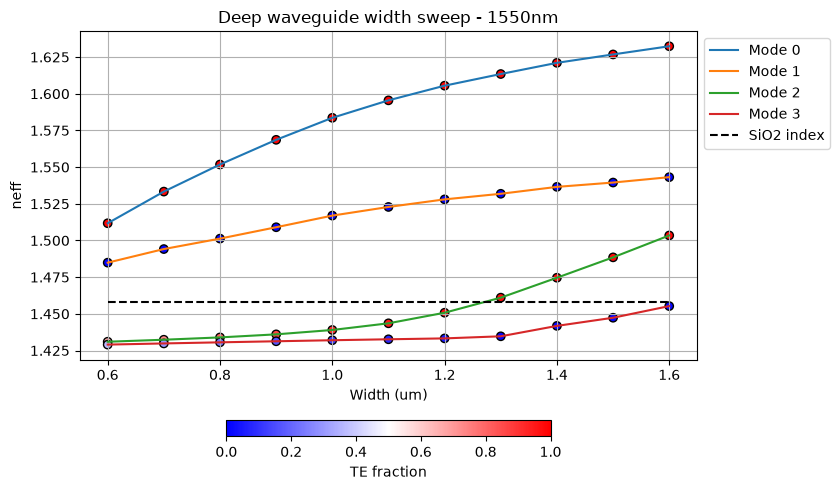

In [113]:
wavelength = 1.55 # Student code here

deep_waveguide = gt.modes.Waveguide(
    wavelength=wavelength,
    core_width=1.2,
    core_material='sin',
    clad_material='sio2',
    core_thickness=300 * nm,
    slab_thickness=0 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.2,
    grid_resolution=20,
)

w = np.linspace(0.6, 1.6, 11) # Student code here

sweep_neff = gt.modes.sweep_n_eff(deep_waveguide,
                             core_width=w)

sweep_tefraction = gt.modes.sweep_fraction_te(deep_waveguide,
                                              core_width=w)

plt.figure(figsize=(10, 5))
for k in range(sweep_neff.shape[1]):
    plt.scatter(w, sweep_neff[:,k].real,edgecolors='k',c=sweep_tefraction.sel(mode_index=k),vmin=0, vmax=1,label = '__nolegend__',cmap='bwr')
    plt.plot(w, sweep_neff[:,k].real,label=f'Mode {k}')

plt.title("Deep waveguide width sweep - 1550nm")
plt.xlabel("Width (um)")
plt.ylabel("neff")
plt.grid()
plt.hlines(np.mean(box_index), xmin=np.min(w), xmax=np.max(w), colors='k', linestyles='dashed',label='SiO2 index')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])
plt.colorbar(orientation='horizontal',fraction=0.04).set_label("TE fraction")

## LO.3. Wavelength behavior

- Let's find the wavelength dependence of the effective index of the SiNx deep waveguide described in LO1. Change the wavelength used at the waveguide cross-section function, it could be a vector also. 

2026-10-09 16:50:41.325 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_e70065e5b5dc42c3.npz.


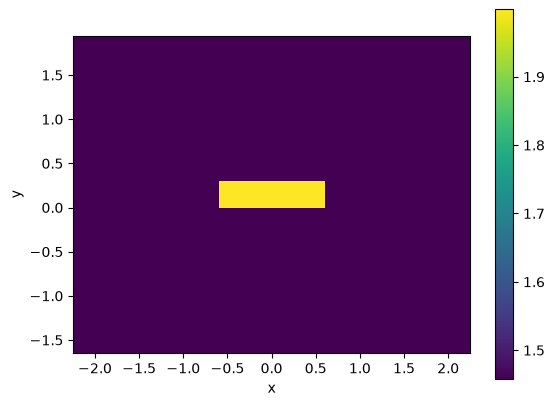

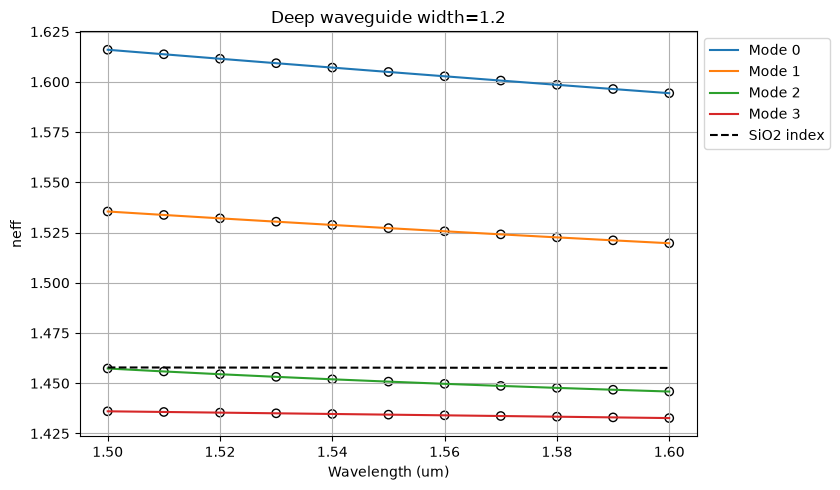

In [114]:
# The wavelength could be a vector also
wavelength = np.linspace(1.5, 1.6, 11) # Student code here. Tip np.linspace()

deep_waveguide = gt.modes.Waveguide(
    wavelength=wavelength,
    core_width=1.2,
    slab_thickness=0.0,
    core_material='sin',
    clad_material='sio2',
    core_thickness=300 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.2,
    grid_resolution=20,
)

res_neff = deep_waveguide.n_eff # In this case, the result is not just a number, is a wavelength-dependent vector
res_te = deep_waveguide.fraction_te # Wavelength-dependent vector
res_tm =deep_waveguide.fraction_tm # Wavelength-dependent vector

deep_waveguide.plot_index()

plt.figure(figsize=(10, 5))
for k in range(res_neff.shape[1]):
    # It's necessary to 'access' each element on the array
    plt.scatter(wavelength, res_neff[:,k].real,edgecolors='k',facecolors='none',label = '__nolegend__')
    plt.plot(wavelength, res_neff[:,k].real,label=f'Mode {k}')
plt.title(f"Deep waveguide width={1.2}")
plt.xlabel("Wavelength (um)")
plt.ylabel("neff")
plt.grid()
# Common error: The box index variable was created in a previous cell. Check the dimensions match
# with the newly created wavelength vector, or re-calculate the box index for the new one.
plt.plot(wavelength, box_index,'k--', label='SiO2 index')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])



- Repeat the analysis for a **shallow**ly etched waveguide with a 150 nm slab heigth. 

2026-10-09 16:50:41.845 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_cf0af488213d9e23.npz.


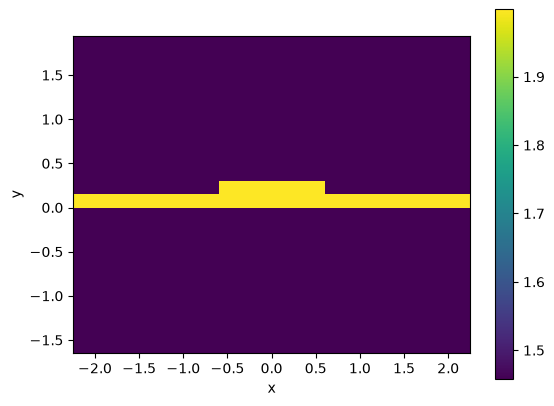

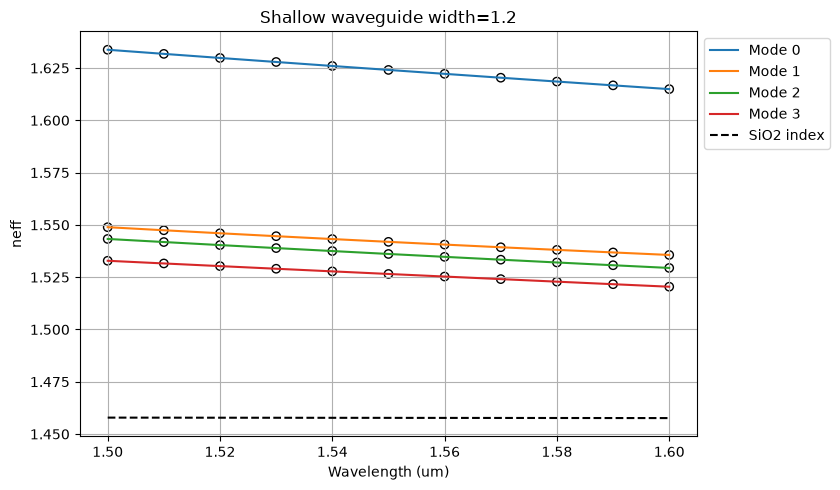

In [115]:
# The wavelength could be a vector also
wavelength = np.linspace(1.5, 1.6, 11) # Student code here. Tip np.linspace()

deep_waveguide = gt.modes.Waveguide(
    wavelength=wavelength,
    core_width=1.2,
    slab_thickness=150*nm,
    core_material='sin',
    clad_material='sio2',
    core_thickness=300 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.2,
    grid_resolution=20,
)

res_neff = deep_waveguide.n_eff # In this case, the result is not just a number, is a wavelength-dependent vector
res_te = deep_waveguide.fraction_te # Wavelength-dependent vector
res_tm =deep_waveguide.fraction_tm # Wavelength-dependent vector

deep_waveguide.plot_index()

plt.figure(figsize=(10, 5))
for k in range(res_neff.shape[1]):
    # It's necessary to 'access' each element on the array
    plt.scatter(wavelength, res_neff[:,k].real,edgecolors='k',facecolors='none',label = '__nolegend__')
    plt.plot(wavelength, res_neff[:,k].real,label=f'Mode {k}')
plt.title(f"Shallow waveguide width={1.2}")
plt.xlabel("Wavelength (um)")
plt.ylabel("neff")
plt.grid()
# Common error: The box index variable was created in a previous cell. Check the dimensions match
# with the newly created wavelength vector, or re-calculate the box index for the new one.
plt.plot(wavelength, box_index,'k--', label='SiO2 index')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])

## LO.4. Waveguide compact model

A compact model of an integrated photonic waveguide is a reduced-order mathematical model that describes the waveguide’s optical behavior—such as phase propagation, loss, and dispersion, using analytical or semi-analytical equations. Consider: 

Consider: 

The transfer function for propagation in a waveguide:

$$
H(\lambda)
= e^{-j\,\gamma(\lambda)\,z}
= e^{-j\,\mathrm{Re}\{\gamma(\lambda)\}\,z}\,
  e^{\mathrm{Im}\{\gamma(\lambda)\}\,z}.
$$

Where 

$$
\beta(\lambda) = \mathrm{Re}\{\gamma(\lambda)\}\,z
= \frac{2\pi}{\lambda}\,n_\mathrm{eff}(\lambda).
$$

Let's model the waveguide's effective index wavelength variation using a second order polynomial:

$$
n_\mathrm{eff}(\lambda)
= n_{1} + n_{2}\,(\lambda-\lambda_{0}) + n_{3}\,(\lambda-\lambda_{0})^{2}
$$

Where 

1. 
$$
n_\mathrm{eff}(\lambda_0) = n_1
$$
2. 
$$
n_g(\lambda_0) = n_1 - n_2\,\lambda_0
$$
3. 
$$
D = -\frac{2\,\lambda_0\,n_3}{c}\;\;[\mathrm{s}^2/\mathrm{m}]
$$

- Find the values for n, ng and D of the following waveguides: 
    - Deep waveguide, height = 300nm, width = 1.2um 
    - Shallow waveguide, core height = 300nm, slab height = 150 nm, width = 1.2um 

**TIP**. Use the Lab.1.Modesolver results (neff vs lambda) as starting point. Fit the results using a second order polynomial (with the lambda_0 shift) and relate the fit results to n_g and D values.

Find the compact models of the following waveguides: 
- Deep waveguide, h=300nm, w=1.2um   
- Shallow waveguide, core h=300nm, slab h=150 nm, w = 1.2um 

## Result:

We start taking $\lambda_0 = 1.55 \mu m$ because is the center of the sweeped range

Using the formulas, we fit the polynomial:

2026-10-09 16:50:42.354 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_e70065e5b5dc42c3.npz.
(11, 4)
[0.995 0.01  0.963 0.05 ]

n_eff TE0 data:
	 [1.616  1.6137 1.6115 1.6093 1.6071 1.6049 1.6028 1.6006 1.5985 1.5964
 1.5944]

	Coefficients:
		n1 = 1.6049	n2 = -0.2162 1/um	n3 = 0.0974 1/um^2

	n_eff = 1.6049
	n_g   = 1.9400
	D   = -1.007e-03 s/m^2

n_eff TM0 data:
	 [1.5355 1.5338 1.5321 1.5304 1.5288 1.5272 1.5256 1.5241 1.5226 1.5211
 1.5197]

	Coefficients:
		n1 = 1.5272	n2 = -0.1580 1/um	n3 = 0.1538 1/um^2

	n_eff = 1.5272
	n_g   = 1.7720
	D   = -1.591e-03 s/m^2


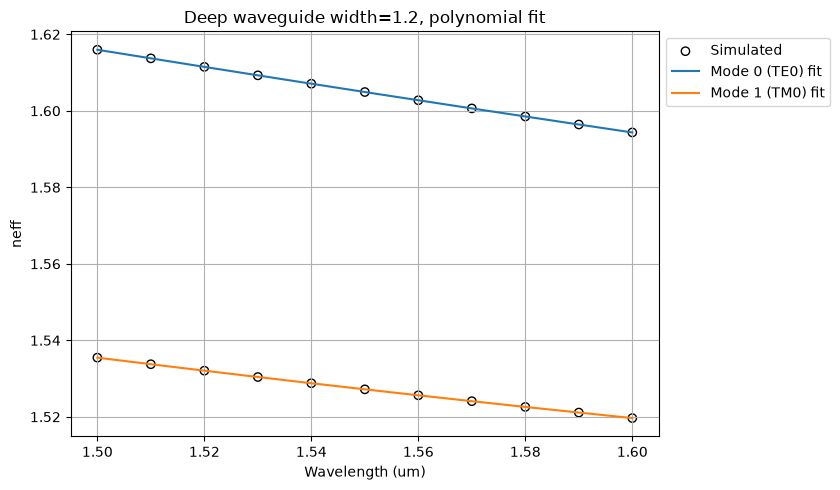

In [116]:
# Deep waveguide

lam0 = 1.55
wavelength = np.linspace(1.5, 1.6, 11)

deep = gt.modes.Waveguide(
    wavelength=wavelength,
    core_width=1.2,
    slab_thickness=0.0,
    core_material='sin',
    clad_material='sio2',
    core_thickness=300 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.2,
    grid_resolution=20,
)

print(deep.n_eff.shape)
print(deep.fraction_te.round(3))

# Ahora para TE0
neff_te0 = deep.n_eff[:, 0].real

n3_te, n2_te, n1_te = np.polyfit(wavelength - lam0, neff_te0, 2)

print("\nn_eff TE0 data:\n\t", neff_te0.round(4))

print("\n\tCoefficients:")
print(f"\t\tn1 = {n1_te:.4f}\tn2 = {n2_te:.4f} 1/um\tn3 = {n3_te:.4f} 1/um^2")

# Ahora siguiendo las formulas de arriba
ng_te = n1_te - n2_te * lam0

D_te_um = -2 * lam0 * n3_te / td.C_0
# convertimos a s/m^2
D_te_ = D_te_um * 1e12

print(f"\n\tn_eff = {n1_te:.4f}")
print(f"\tn_g   = {ng_te:.4f}")
print(f"\tD   = {D_te_:.3e} s/m^2")

# Ahora para TM0
neff_tm0 = deep.n_eff[:, 1].real

n3_tm, n2_tm, n1_tm = np.polyfit(wavelength - lam0, neff_tm0, 2)

print("\nn_eff TM0 data:\n\t", neff_tm0.round(4))

print("\n\tCoefficients:")
print(f"\t\tn1 = {n1_tm:.4f}\tn2 = {n2_tm:.4f} 1/um\tn3 = {n3_tm:.4f} 1/um^2")

# Ahora siguiendo las formulas de arriba
ng_tm = n1_tm - n2_tm * lam0

D_tm_um = -2 * lam0 * n3_tm / td.C_0
# convertimos a s/m^2
D_tm_ = D_tm_um * 1e12

print(f"\n\tn_eff = {n1_tm:.4f}")
print(f"\tn_g   = {ng_tm:.4f}")
print(f"\tD   = {D_tm_:.3e} s/m^2")

# Finally, we plot te vs lambda and tm vs lambda
lam_fit = np.linspace(1.5, 1.6, 200)
fit_te0 = np.polyval([n3_te, n2_te, n1_te], lam_fit - lam0)
fit_tm0 = np.polyval([n3_tm, n2_tm, n1_tm], lam_fit - lam0)

plt.figure(figsize=(10, 5))
plt.scatter(wavelength, neff_te0, edgecolors='k', facecolors='none', label='Simulated')
plt.scatter(wavelength, neff_tm0, edgecolors='k', facecolors='none', label='__nolegend__')
plt.plot(lam_fit, fit_te0, color='C0', label='Mode 0 (TE0) fit')
plt.plot(lam_fit, fit_tm0, color='C1', label='Mode 1 (TM0) fit')
plt.title(f"Deep waveguide width={1.2}, polynomial fit")
plt.xlabel("Wavelength (um)")
plt.ylabel("neff")
plt.grid()
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])




2026-10-09 16:50:42.644 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_cf0af488213d9e23.npz.
(11, 4)
[0.997 0.706 0.175 1.   ]

n_eff TE0 data:
	 [1.6337 1.6318 1.6298 1.6279 1.626  1.6241 1.6222 1.6204 1.6185 1.6167
 1.6149]

	Coefficients:
		n1 = 1.6241	n2 = -0.1882 1/um	n3 = 0.0957 1/um^2

	n_eff = 1.6241
	n_g   = 1.9158
	D   = -9.895e-04 s/m^2

n_eff TM0 data:
	 [1.5433 1.5418 1.5404 1.5389 1.5375 1.5361 1.5347 1.5334 1.532  1.5307
 1.5294]

	Coefficients:
		n1 = 1.5361	n2 = -0.1387 1/um	n3 = 0.0980 1/um^2

	n_eff = 1.5361
	n_g   = 1.7510
	D   = -1.013e-03 s/m^2


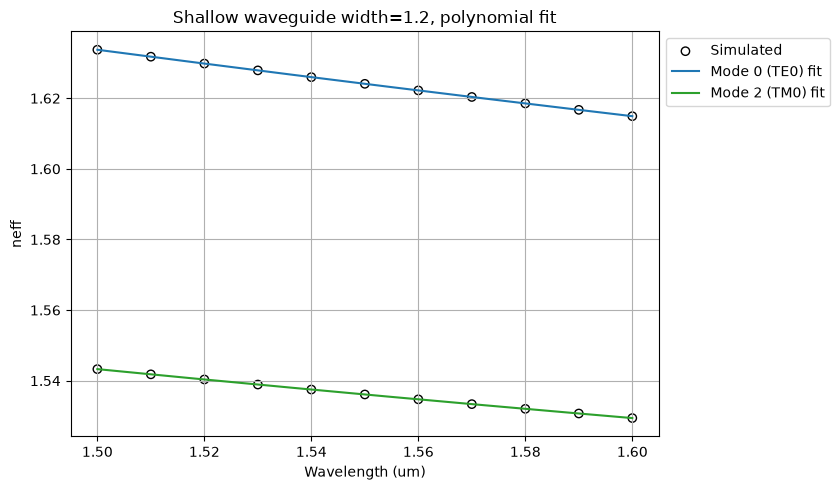

In [117]:
#SHALLOW WAVEGUIDE
lam0 = 1.55
wavelength = np.linspace(1.5, 1.6, 11)

shallow = gt.modes.Waveguide(
    wavelength=wavelength,
    core_width=1.2,
    slab_thickness=150 * nm,
    core_material='sin',
    clad_material='sio2',
    core_thickness=300 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.2,
    grid_resolution=20,
)

print(shallow.n_eff.shape)
print(shallow.fraction_te.round(3))

# Ahora para TE0
neff_te0_sh = shallow.n_eff[:, 0].real

n3_te_sh, n2_te_sh, n1_te_sh = np.polyfit(wavelength - lam0, neff_te0_sh, 2)

print("\nn_eff TE0 data:\n\t", neff_te0_sh.round(4))

print("\n\tCoefficients:")
print(f"\t\tn1 = {n1_te_sh:.4f}\tn2 = {n2_te_sh:.4f} 1/um\tn3 = {n3_te_sh:.4f} 1/um^2")

# Ahora siguiendo las formulas de arriba
ng_te_sh = n1_te_sh - n2_te_sh * lam0

D_te_um_sh = -2 * lam0 * n3_te_sh / td.C_0
# convertimos a s/m^2
D_te_sh = D_te_um_sh * 1e12

print(f"\n\tn_eff = {n1_te_sh:.4f}")
print(f"\tn_g   = {ng_te_sh:.4f}")
print(f"\tD   = {D_te_sh:.3e} s/m^2")

# Ahora para TM0
neff_tm0_sh = shallow.n_eff[:, 2].real

n3_tm_sh, n2_tm_sh, n1_tm_sh = np.polyfit(wavelength - lam0, neff_tm0_sh, 2)

print("\nn_eff TM0 data:\n\t", neff_tm0_sh.round(4))

print("\n\tCoefficients:")
print(f"\t\tn1 = {n1_tm_sh:.4f}\tn2 = {n2_tm_sh:.4f} 1/um\tn3 = {n3_tm_sh:.4f} 1/um^2")

# Ahora siguiendo las formulas de arriba
ng_tm_sh = n1_tm_sh - n2_tm_sh * lam0

D_tm_um_sh = -2 * lam0 * n3_tm_sh / td.C_0
# convertimos a s/m^2
D_tm_sh = D_tm_um_sh * 1e12

print(f"\n\tn_eff = {n1_tm_sh:.4f}")
print(f"\tn_g   = {ng_tm_sh:.4f}")
print(f"\tD   = {D_tm_sh:.3e} s/m^2")

# Finally, we plot te vs lambda and tm vs lambda
lam_fit_sh = np.linspace(1.5, 1.6, 200)
fit_te0_sh = np.polyval([n3_te_sh, n2_te_sh, n1_te_sh], lam_fit_sh - lam0)
fit_tm0_sh = np.polyval([n3_tm_sh, n2_tm_sh, n1_tm_sh], lam_fit_sh - lam0)

plt.figure(figsize=(10, 5))
plt.scatter(wavelength, neff_te0_sh, edgecolors='k', facecolors='none', label='Simulated')
plt.scatter(wavelength, neff_tm0_sh, edgecolors='k', facecolors='none', label='__nolegend__')
plt.plot(lam_fit_sh, fit_te0_sh, color='C0', label='Mode 0 (TE0) fit')
plt.plot(lam_fit_sh, fit_tm0_sh, color='C2', label='Mode 2 (TM0) fit')
plt.title(f"Shallow waveguide width={1.2}, polynomial fit")
plt.xlabel("Wavelength (um)")
plt.ylabel("neff")
plt.grid()
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])




# Assignment 

All the past simulations were done considering as core material de Silicon Nitride (SiNx) and Silicon Dioxide (SiO2) as cladding material. Now, **simulate the Silicon-On-Insulator technology changing the core material to Silicon (Si)**. In this case, the dimensions will be **220 nm heigth**. 
1. Repeat the LO.2. width behavior simulations, now sweeping in a 300nm - 1um range. considering the updated materials and dimensions. 
2. Repeat the LO.3. wavelength dependence analysis, using a width that allows to use the waveguide in a monomode region.
3. **Compare the SiNx and SOI technologies** 

## Repeated LO.2. Width dependence

  0%|          | 0/29 [00:00<?, ?it/s]

2026-10-09 16:50:42.931 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_664349a06b244eb3.npz.
2026-10-09 16:50:42.934 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_1f0e5264be8fabe0.npz.
2026-10-09 16:50:42.937 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_a22c343f6dc21968.npz.
2026-10-09 16:50:42.940 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_bf1fd64505d6ade3.npz.
2026-10-09 16:50:42.942 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_81901cbf3aa1d3fb.npz.
2026-10-09 16:50:42.947 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_4c7e05fb0f01b566.npz.
2026-10-09 16:50:42.951 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_7f7c3d22bd92b182.npz.
2026-10-09 16:50:42.953 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_26daa819d217ebd3.npz.


  0%|          | 0/29 [00:00<?, ?it/s]

2026-10-09 16:50:43.043 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_664349a06b244eb3.npz.
2026-10-09 16:50:43.046 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_1f0e5264be8fabe0.npz.
2026-10-09 16:50:43.438 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_a22c343f6dc21968.npz.
2026-10-09 16:50:43.442 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_bf1fd64505d6ade3.npz.
2026-10-09 16:50:43.444 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_81901cbf3aa1d3fb.npz.
2026-10-09 16:50:43.445 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_4c7e05fb0f01b566.npz.
2026-10-09 16:50:43.449 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_7f7c3d22bd92b182.npz.
2026-10-09 16:50:43.452 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_26daa819d217ebd3.npz.


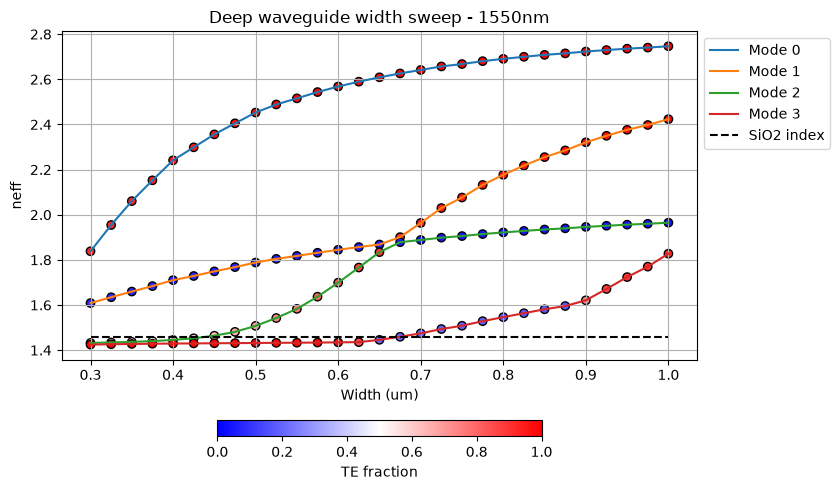

In [118]:
wavelength = 1.55 # Student code here

deep_waveguide = gt.modes.Waveguide(
    wavelength=wavelength,
    core_width=1.2,
    core_material='si',
    clad_material='sio2',
    core_thickness=220 * nm,
    slab_thickness=0 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.2,
    grid_resolution=60,
)

w = np.linspace(0.3, 1, 29) # Student code here

sweep_neff = gt.modes.sweep_n_eff(deep_waveguide,
                             core_width=w)

sweep_tefraction = gt.modes.sweep_fraction_te(deep_waveguide,
                                              core_width=w)

plt.figure(figsize=(10, 5))
for k in range(sweep_neff.shape[1]):
    plt.scatter(w, sweep_neff[:,k].real,edgecolors='k',c=sweep_tefraction.sel(mode_index=k),vmin=0, vmax=1,label = '__nolegend__',cmap='bwr')
    plt.plot(w, sweep_neff[:,k].real,label=f'Mode {k}')

plt.title("Deep waveguide width sweep - 1550nm")
plt.xlabel("Width (um)")
plt.ylabel("neff")
plt.grid()
plt.hlines(np.mean(box_index), xmin=np.min(w), xmax=np.max(w), colors='k', linestyles='dashed',label='SiO2 index')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])
plt.colorbar(orientation='horizontal',fraction=0.04).set_label("TE fraction")

## Repeated LO.3. Wavelength behavior

### DEEP


2026-10-09 16:50:43.939 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_c78d177e1f1182c3.npz.


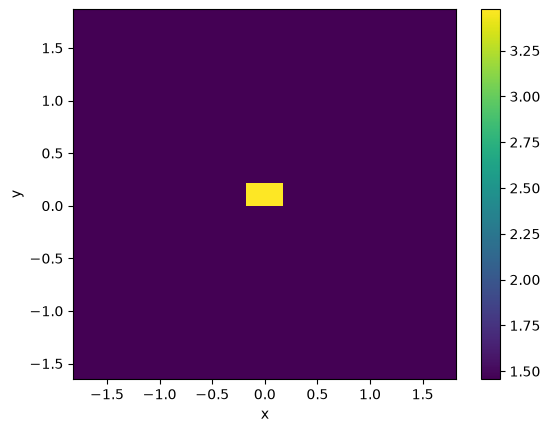

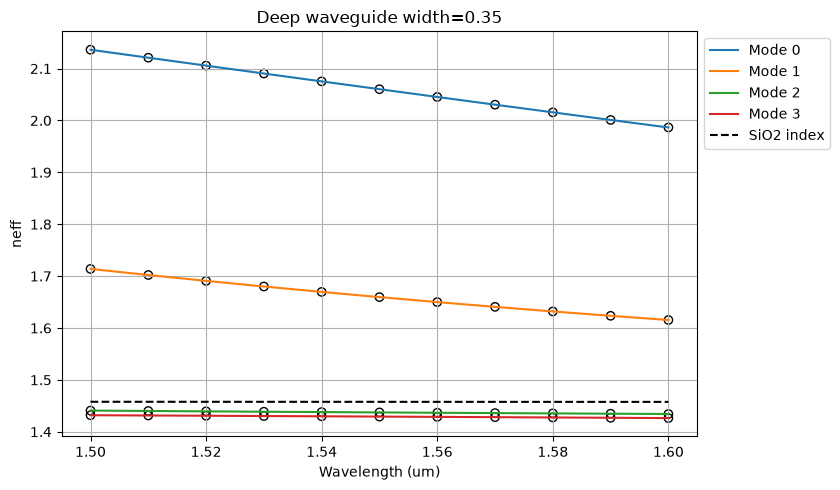

In [119]:
# The wavelength could be a vector also
wavelength = np.linspace(1.5, 1.6, 11) # Student code here. Tip np.linspace()

deep_waveguide = gt.modes.Waveguide(
    wavelength=wavelength,
    core_width=0.35,
    slab_thickness=0.0,
    core_material='si',
    clad_material='sio2',
    core_thickness=220 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.2,
    grid_resolution=60,
)

res_neff = deep_waveguide.n_eff # In this case, the result is not just a number, is a wavelength-dependent vector
res_te = deep_waveguide.fraction_te # Wavelength-dependent vector
res_tm =deep_waveguide.fraction_tm # Wavelength-dependent vector

deep_waveguide.plot_index()

plt.figure(figsize=(10, 5))
for k in range(res_neff.shape[1]):
    # It's necessary to 'access' each element on the array
    plt.scatter(wavelength, res_neff[:,k].real,edgecolors='k',facecolors='none',label = '__nolegend__')
    plt.plot(wavelength, res_neff[:,k].real,label=f'Mode {k}')
plt.title(f"Deep waveguide width={0.35}")
plt.xlabel("Wavelength (um)")
plt.ylabel("neff")
plt.grid()
# Common error: The box index variable was created in a previous cell. Check the dimensions match
# with the newly created wavelength vector, or re-calculate the box index for the new one.
plt.plot(wavelength, box_index,'k--', label='SiO2 index')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])



### SHALLOW

2026-10-09 16:50:44.468 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_3c7b0190998e215b.npz.


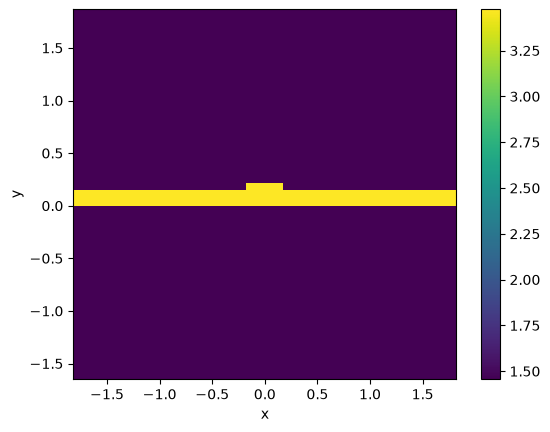

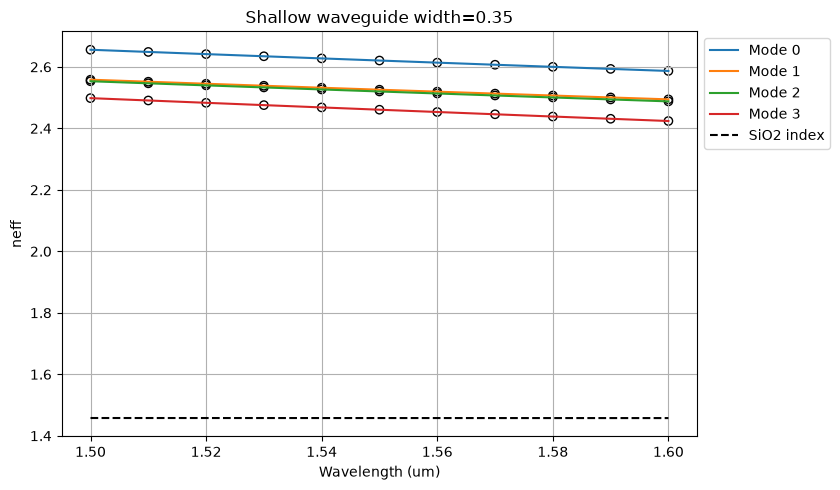

In [120]:
# The wavelength could be a vector also
wavelength = np.linspace(1.5, 1.6, 11) # Student code here. Tip np.linspace()

deep_waveguide = gt.modes.Waveguide(
    wavelength=wavelength,
    core_width=0.35,
    slab_thickness=150*nm,
    core_material='si',
    clad_material='sio2',
    core_thickness=220 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.2,
    grid_resolution=60,
)

res_neff = deep_waveguide.n_eff # In this case, the result is not just a number, is a wavelength-dependent vector
res_te = deep_waveguide.fraction_te # Wavelength-dependent vector
res_tm =deep_waveguide.fraction_tm # Wavelength-dependent vector

deep_waveguide.plot_index()

plt.figure(figsize=(10, 5))
for k in range(res_neff.shape[1]):
    # It's necessary to 'access' each element on the array
    plt.scatter(wavelength, res_neff[:,k].real,edgecolors='k',facecolors='none',label = '__nolegend__')
    plt.plot(wavelength, res_neff[:,k].real,label=f'Mode {k}')
plt.title(f"Shallow waveguide width={0.35}")
plt.xlabel("Wavelength (um)")
plt.ylabel("neff")
plt.grid()
# Common error: The box index variable was created in a previous cell. Check the dimensions match
# with the newly created wavelength vector, or re-calculate the box index for the new one.
plt.plot(wavelength, box_index,'k--', label='SiO2 index')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])

## Grading

LO.1. 1 Point <br> 
LO.2. 2 Points <br> 
LO.3. 2 Points <br> 
LO.4. 2 Points <br> 
As. (Up to) 3 Points
